#### Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset, WeightedRandomSampler

import numpy as np
import copy
import random

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

#### Dataset

In [2]:
!pip install -q kaggle

import os

os.environ['KAGGLE_USERNAME'] = "aruna4"
os.environ['KAGGLE_KEY'] = "fabb0946078c052efc978557cfd54477"

!kaggle datasets download -d nodoubttome/skin-cancer9-classesisic
!unzip -q skin-cancer9-classesisic.zip -d skin_cancer_data

base_path = "skin_cancer_data/Skin cancer ISIC The International Skin Imaging Collaboration"

train_path = os.path.join(base_path, "Train")
test_path  = os.path.join(base_path, "Test")

Dataset URL: https://www.kaggle.com/datasets/nodoubttome/skin-cancer9-classesisic
License(s): other
100% 786M/786M [00:09<00:00, 91.2MB/s]



#### Parameters

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS_FIRST = 30
EPOCHS_INC = 25

LR_FIRST = 3e-5
LR_INC = 1e-5

BATCH_SIZE = 32

KD_T = 4
LAMBDA_KD = 1.0
LAMBDA_FEAT = 1.0

MEMORY_PER_CLASS = 120

LABEL_SMOOTHING = 0.1

USE_LOGIT_CORRECTION = True

#### Augmentation

In [4]:
from torchvision import transforms

# TRAIN TRANSFORMS

train_transform = transforms.Compose([

    # Random zoom & crop
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.8, 1.0),
        ratio=(0.9, 1.1)
    ),

    # Flip augmentations
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    # Controlled rotation
    transforms.RandomRotation(degrees=15),

    # Dermoscopy lighting variation
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.05
    ),

    # Small spatial changes
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    # Focus variation
    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1, 2.0)
    ),

    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),

    # Hair / artifact simulation
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.08),
        ratio=(0.3, 3.3)
    )
])

# TEST TRANSFORMS

test_transform = transforms.Compose([

    transforms.Resize(256),
    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#### Load Dataset

In [5]:
full_train_dataset = torchvision.datasets.ImageFolder(
    root=train_path,
    transform=train_transform
)

full_test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=test_transform
)

num_total_classes = len(full_train_dataset.classes)
print("Total Classes:", num_total_classes)

Total Classes: 9


#### Incremental Task Split (3 Classes Per Task)

In [6]:
class_names = sorted(full_train_dataset.classes)

task_splits = [
    class_names[0:3],
    class_names[3:6],
    class_names[6:9]
]

for i, t in enumerate(task_splits):
    print(f"Task {i+1} classes:", t)

Task 1 classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Task 2 classes: ['melanoma', 'nevus', 'pigmented benign keratosis']
Task 3 classes: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']


#### Task Datasets

In [7]:
task_datasets = []

class_to_idx = full_train_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

for task_classes in task_splits:

    class_ids = [class_to_idx[c] for c in task_classes]

    indices = [
        i for i, (_, label) in enumerate(full_train_dataset.samples)
        if label in class_ids
    ]

    subset = Subset(full_train_dataset, indices)

    task_datasets.append(subset)

print("Total Tasks:", len(task_datasets))

Total Tasks: 3


#### Initialize Vision Tansformer Model

In [8]:
model = torchvision.models.vit_b_16(
    weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1
)

in_features = model.heads.head.in_features

model.heads.head = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, num_total_classes)
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 95.7MB/s]


#### Freeze Backbone After Task 1

In [9]:
def freeze_backbone(model):

    for name, param in model.named_parameters():

        # Train last 4 transformer blocks + classifier
        if (
            "encoder_layer_8" in name or
            "encoder_layer_9" in name or
            "encoder_layer_10" in name or
            "encoder_layer_11" in name or
            "heads" in name
        ):
            param.requires_grad = True
        else:
            param.requires_grad = False

def kd_loss(student_logits, teacher_logits, T=4):

    student_log_prob = F.log_softmax(student_logits / T, dim=1)
    teacher_prob = F.softmax(teacher_logits / T, dim=1)

    loss = F.kl_div(
        student_log_prob,
        teacher_prob,
        reduction='batchmean'
    )

    return loss * (T * T)

def feature_distill_loss(new_feat, old_feat):
    return F.mse_loss(new_feat, old_feat)

#### Feature Extraction (ViT CLS Token)

In [10]:
def extract_features(model, x):

    x = model._process_input(x)
    n = x.shape[0]

    cls_token = model.class_token.expand(n, -1, -1)

    x = torch.cat((cls_token, x), dim=1)

    # add positional embedding
    x = x + model.encoder.pos_embedding
    x = model.encoder.dropout(x)

    x = model.encoder.layers(x)

    # CLS token
    return x[:, 0]

#### KD + Feature Distillation

In [11]:
def kd_loss(student_logits, teacher_logits):

    T = KD_T

    student_log_prob = F.log_softmax(student_logits / T, dim=1)
    teacher_prob = F.softmax(teacher_logits / T, dim=1)

    loss = F.kl_div(
        student_log_prob,
        teacher_prob,
        reduction='batchmean'
    )

    return loss * (T * T)


def feature_distill_loss(new_feat, old_feat):

    new_feat = F.normalize(new_feat, dim=1)
    old_feat = F.normalize(old_feat, dim=1)

    return F.mse_loss(new_feat, old_feat)

#### Balanced Sampler

In [12]:
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np

def get_loader(dataset, batch_size=32):

    labels = [label for _, label in dataset]

    class_counts = np.bincount(labels)

    class_weights = 1. / (class_counts + 1e-6)
    class_weights = class_weights / class_weights.sum()

    sample_weights = [class_weights[label] for label in labels]

    sampler = WeightedRandomSampler(
        sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        sampler=sampler,
        num_workers=2,
        pin_memory=True
    )

    return loader

#### Memory Buffer

In [13]:
memory_data = []
memory_labels = []

def update_memory(dataset):

    global memory_data, memory_labels

    loader = DataLoader(dataset, batch_size=1, shuffle=True)

    class_counter = {}

    for img, label in loader:

        label = label.item()

        if class_counter.get(label, 0) < MEMORY_PER_CLASS:

            memory_data.append(img.squeeze(0).cpu())
            memory_labels.append(label)

            class_counter[label] = class_counter.get(label, 0) + 1

#### CIL Evaluation Function

In [14]:
def evaluate_task(model, dataset):

    model.eval()

    loader = DataLoader(dataset, batch_size=32, shuffle=False)

    correct = 0
    total = 0

    class_correct = {}
    class_total = {}

    with torch.no_grad():

        for imgs, labels in loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)

            #if USE_LOGIT_CORRECTION and len(seen_classes) > len(current_classes):
                #bias_factor = len(current_classes) / len(seen_classes)
                #outputs[:, seen_classes[:-len(current_classes)]] *= bias_factor

            # Apply same bias correction during evaluation
            #if len(seen_classes) > 3:
                #bias_factor = len(current_classes) / len(seen_classes)
                #outputs[:, seen_classes[:-len(current_classes)]] *= bias_factor

            # restrict predictions to seen classes
            outputs_seen = outputs[:, seen_classes]

            preds_idx = outputs_seen.argmax(dim=1)

            preds = torch.tensor(seen_classes, device=device)[preds_idx]

            for i in range(len(labels)):

                label = labels[i].item()
                pred = preds[i].item()

                if label not in class_correct:
                    class_correct[label] = 0
                    class_total[label] = 0

                if pred == label:
                    class_correct[label] += 1

                class_total[label] += 1

                correct += (pred == label)
                total += 1

    accuracy = correct / total

    class_acc = {
        c: class_correct[c] / class_total[c]
        for c in class_total
    }

    return accuracy, class_acc

#### CutMix Function

In [15]:
import numpy as np

def rand_bbox(size, lam):

    W = size[3]
    H = size[2]

    cut_rat = np.sqrt(1. - lam)

    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)

    cx = np.random.randint(W)
    cy = np.random.randint(H)

    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bby2 = np.clip(cy + cut_h // 2, 0, H)

    return bbx1, bby1, bbx2, bby2


def cutmix_data(x, y, alpha=1.0):

    lam = np.random.beta(alpha, alpha)

    batch_size = x.size(0)

    index = torch.randperm(batch_size).to(x.device)

    bbx1, bby1, bbx2, bby2 = rand_bbox(x.size(), lam)

    x[:, :, bby1:bby2, bbx1:bbx2] = x[index, :, bby1:bby2, bbx1:bbx2]

    y_a, y_b = y, y[index]

    lam = 1 - ((bbx2-bbx1)*(bby2-bby1)/(x.size(-1)*x.size(-2)))

    return x, y_a, y_b, lam

#### Training Function

In [16]:
def train_task(model, dataset,
               seen_classes,
               old_model=None,
               first_task=False,
               current_classes=None):

    print("Seen classes inside train:", seen_classes)

    epochs = EPOCHS_FIRST if first_task else EPOCHS_INC

    model.train()

    trainable_params = [name for name, p in model.named_parameters() if p.requires_grad]
    print("Trainable Parameters:", trainable_params)

    lr = LR_FIRST if first_task else LR_INC

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    # CLASS WEIGHTS

    import numpy as np

    all_labels = [label for _, label in dataset]

    class_counts_full = np.bincount(all_labels)

    class_counts_seen = [class_counts_full[c] for c in seen_classes]

    weights = 1.0 / (np.array(class_counts_seen) + 1e-6)
    weights = weights / weights.sum()

    weights = torch.tensor(weights, dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)

    loader = get_loader(dataset)

    label_map = {cls: i for i, cls in enumerate(seen_classes)}


    # TRAIN LOOP

    for epoch in range(epochs):

        total_loss = 0

        for imgs, labels in loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            use_cutmix = np.random.rand() < 0.5

            if use_cutmix:
                imgs, targets_a, targets_b, lam = cutmix_data(imgs, labels)

            # Forward pass
            outputs = model(imgs)

            # Logit Bias Correction
            #if USE_LOGIT_CORRECTION and not first_task:
                #bias_factor = len(current_classes) / len(seen_classes)
                #outputs[:, seen_classes[:-len(current_classes)]] *= bias_factor

            outputs_seen = outputs[:, seen_classes]

            mapped_labels = torch.tensor(
                [label_map[l.item()] for l in labels],
                dtype=torch.long
            ).to(device)

            if use_cutmix:

                mapped_a = torch.tensor(
                    [label_map[l.item()] for l in targets_a],
                    dtype=torch.long
                ).to(device)

                mapped_b = torch.tensor(
                    [label_map[l.item()] for l in targets_b],
                    dtype=torch.long
                ).to(device)

                ce = lam * criterion(outputs_seen, mapped_a) + \
                     (1-lam) * criterion(outputs_seen, mapped_b)

            else:

                ce = criterion(outputs_seen, mapped_labels)

            loss = ce

            # KNOWLEDGE DISTILLATION

            if old_model is not None:

                old_class_count = len(seen_classes) - len(current_classes)

                if old_class_count > 0:

                    with torch.no_grad():
                        old_outputs = old_model(imgs)

                    old_class_ids = seen_classes[:-len(current_classes)]

                    kd = kd_loss(
                        outputs[:, old_class_ids],
                        old_outputs[:, old_class_ids]
                    )

                    loss = ce + LAMBDA_KD * kd

            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            optimizer.step()

            total_loss += loss.item()

        scheduler.step()

        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Loss: {total_loss/len(loader):.4f}"
        )

#### Continual Learning Loop

In [17]:
# CONTINUAL LEARNING LOOP

seen_classes = []

num_tasks = len(task_datasets)
accuracy_matrix = np.zeros((num_tasks, num_tasks))

old_model = None

for task_id, task_dataset in enumerate(task_datasets):

    current_classes = [
        full_train_dataset.class_to_idx[c]
        for c in task_splits[task_id]
    ]

    seen_classes.extend(current_classes)
    seen_classes = sorted(seen_classes)

    print("\n==============================")
    print(f"        TASK {task_id+1}")
    print("==============================")

    # FIRST TASK

    if task_id == 0:

        for p in model.parameters():
            p.requires_grad = True

        train_task(
            model,
            task_dataset,
            seen_classes=seen_classes,
            first_task=True,
            current_classes=current_classes
        )

        freeze_backbone(model)

    # INCREMENTAL TASKS

    else:

        old_model = copy.deepcopy(model)
        old_model.eval()

        for p in old_model.parameters():
            p.requires_grad = False

        combined = list(task_dataset)

        # Add replay memory
        for img, label in zip(memory_data, memory_labels):
            combined.append((img, label))

        train_task(
            model,
            combined,
            seen_classes=seen_classes,
            old_model=old_model,
            first_task=False,
            current_classes=current_classes
        )

    # UPDATE MEMORY

    update_memory(task_dataset)

    # BALANCED FINE-TUNING

    print("\nRunning Balanced Fine-Tuning...")

    balanced_data = [
        (img, label)
        for img, label in zip(memory_data, memory_labels)
        if label in seen_classes
    ]

    balanced_loader = DataLoader(
        balanced_data,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    bft_criterion = nn.CrossEntropyLoss()

    model.train()

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LR_INC * 0.5
    )

    for epoch in range(3):

        for imgs, labels in balanced_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(imgs)

            outputs_seen = outputs[:, seen_classes]

            mapped_labels = torch.tensor(
                [seen_classes.index(l.item()) for l in labels],
                dtype=torch.long
            ).to(device)

            loss = bft_criterion(outputs_seen, mapped_labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            optimizer.step()

    # EVALUATION

    print("\n--- Evaluation After Task", task_id+1, "---")

    for eval_id in range(task_id + 1):

        acc, class_acc = evaluate_task(model, task_datasets[eval_id])
        accuracy_matrix[task_id, eval_id] = acc

        print(f"\nTask {eval_id+1} Accuracy: {acc:.4f}")

        print("Class-wise Accuracy:")

        for cls in sorted(class_acc.keys()):
            class_name = full_train_dataset.classes[cls]
            print(f"  {class_name}: {class_acc[cls]:.4f}")

    # CONTINUAL LEARNING METRICS

    T = task_id + 1

    # Average Accuracy
    AA = np.mean(accuracy_matrix[task_id, :T])

    # Average Incremental Accuracy
    AIA = np.mean([
        np.mean(accuracy_matrix[i, :i+1])
        for i in range(T)
    ])

    # Forgetting
    forgetting = []
    for i in range(T-1):

        max_prev = np.max(accuracy_matrix[:T, i])

        forgetting.append(
            max_prev - accuracy_matrix[T-1, i]
        )

    forgetting_score = np.mean(forgetting) if forgetting else 0

    # Backward Transfer
    BWT = np.mean([
        accuracy_matrix[T-1, i] - accuracy_matrix[i, i]
        for i in range(T-1)
    ]) if T > 1 else 0

    # Forward Transfer
    FWT = np.mean([
        accuracy_matrix[i-1, i]
        for i in range(1, T)
    ]) if T > 1 else 0

    print("\n===== CIL Metrics After Task", T, "=====")

    print(f"Average Accuracy (AA): {AA:.4f}")
    print(f"Average Incremental Accuracy (AIA): {AIA:.4f}")
    print(f"Forgetting (F): {forgetting_score:.4f}")
    print(f"Backward Transfer (BWT): {BWT:.4f}")
    print(f"Forward Transfer (FWT): {FWT:.4f}")


        TASK 1
Seen classes inside train: [0, 1, 2]
Trainable Parameters: ['class_token', 'conv_proj.weight', 'conv_proj.bias', 'encoder.pos_embedding', 'encoder.layers.encoder_layer_0.ln_1.weight', 'encoder.layers.encoder_layer_0.ln_1.bias', 'encoder.layers.encoder_layer_0.self_attention.in_proj_weight', 'encoder.layers.encoder_layer_0.self_attention.in_proj_bias', 'encoder.layers.encoder_layer_0.self_attention.out_proj.weight', 'encoder.layers.encoder_layer_0.self_attention.out_proj.bias', 'encoder.layers.encoder_layer_0.ln_2.weight', 'encoder.layers.encoder_layer_0.ln_2.bias', 'encoder.layers.encoder_layer_0.mlp.0.weight', 'encoder.layers.encoder_layer_0.mlp.0.bias', 'encoder.layers.encoder_layer_0.mlp.3.weight', 'encoder.layers.encoder_layer_0.mlp.3.bias', 'encoder.layers.encoder_layer_1.ln_1.weight', 'encoder.layers.encoder_layer_1.ln_1.bias', 'encoder.layers.encoder_layer_1.self_attention.in_proj_weight', 'encoder.layers.encoder_layer_1.self_attention.in_proj_bias', 'encoder.lay

#### Final Evaluation

In [18]:
# CLASSIFICATION REPORT

from sklearn.metrics import classification_report
from torch.utils.data import DataLoader
import torch
import numpy as np

model.eval()

all_true = []
all_pred = []
all_target_names = []

for task_id, task_classes in enumerate(task_splits):

    print("\n============================================================")
    print(f"CLASSIFICATION REPORT FOR TASK {task_id+1}")
    print("Classes:", task_classes)
    print("============================================================")

    # get indices of task classes
    task_class_indices = [class_to_idx[c] for c in task_classes]
    task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

    # dataset filtered for current task classes
    task_indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = torch.utils.data.Subset(full_test_dataset, task_indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # restrict predictions to task classes only
            outputs_task = outputs[:, task_class_indices]

            preds_idx = torch.argmax(outputs_task, dim=1)
            preds = task_class_indices_tensor[preds_idx]

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    print(classification_report(
        y_true,
        y_pred,
        labels=task_class_indices,
        target_names=task_classes,
        digits=4
    ))

    all_true.extend(y_true)
    all_pred.extend(y_pred)
    all_target_names.extend(task_classes)

print("\n============================================================")
print("CLASSIFICATION REPORT")
print("============================================================")

unique_labels = sorted(list(set(all_true)))

print(classification_report(
    all_true,
    all_pred,
    labels=unique_labels,
    target_names=[idx_to_class[i] for i in unique_labels],
    digits=4
))


CLASSIFICATION REPORT FOR TASK 1
Classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
                      precision    recall  f1-score   support

   actinic keratosis     1.0000    0.7500    0.8571        16
basal cell carcinoma     0.8421    1.0000    0.9143        16
      dermatofibroma     0.9412    1.0000    0.9697        16

            accuracy                         0.9167        48
           macro avg     0.9278    0.9167    0.9137        48
        weighted avg     0.9278    0.9167    0.9137        48


CLASSIFICATION REPORT FOR TASK 2
Classes: ['melanoma', 'nevus', 'pigmented benign keratosis']
                            precision    recall  f1-score   support

                  melanoma     0.8000    0.2500    0.3810        16
                     nevus     0.6087    0.8750    0.7179        16
pigmented benign keratosis     0.6500    0.8125    0.7222        16

                  accuracy                         0.6458        48
                 ma

In [19]:
# TRAIN AND TEST ACCURACY

from torch.utils.data import DataLoader, Subset
import torch

model.eval()

def compute_task_aware_accuracy(dataset):

    total_correct = 0
    total_samples = 0

    for task_id, task_classes in enumerate(task_splits):

        # class indices for this task
        task_class_indices = [class_to_idx[c] for c in task_classes]
        task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

        # filter dataset samples belonging to this task
        indices = [i for i, (_, label) in enumerate(dataset) if label in task_class_indices]
        subset = Subset(dataset, indices)

        loader = DataLoader(subset, batch_size=32, shuffle=False)

        with torch.no_grad():
            for images, labels in loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                # restrict predictions to task classes
                outputs_task = outputs[:, task_class_indices]

                preds_idx = torch.argmax(outputs_task, dim=1)
                preds = task_class_indices_tensor[preds_idx]

                total_correct += (preds == labels).sum().item()
                total_samples += labels.size(0)

    return total_correct / total_samples if total_samples > 0 else 0.0


# TRAIN ACCURACY
train_task_aware_acc = compute_task_aware_accuracy(full_train_dataset)
print(f"TRAIN Accuracy: {train_task_aware_acc:.4f}")

# TEST ACCURACY
test_task_aware_acc = compute_task_aware_accuracy(full_test_dataset)
print(f"TEST Accuracy: {test_task_aware_acc:.4f}")

TRAIN Accuracy: 0.9075
TEST Accuracy: 0.8051


In [37]:
# CLASSIFICATION REPORT

from sklearn.metrics import classification_report
from torch.utils.data import DataLoader, Subset
import torch
import numpy as np

model.eval()

all_true = []
all_pred = []

for task_id, task_classes in enumerate(task_splits):

    # class indices for this task
    task_class_indices = [class_to_idx[c] for c in task_classes]
    task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

    # select only samples of this task from full test set
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # task-aware prediction: restrict only to current task classes
            outputs_task = outputs[:, task_class_indices]

            preds_idx = torch.argmax(outputs_task, dim=1)
            preds = task_class_indices_tensor[preds_idx]

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(preds.cpu().numpy())

# reverse mapping if not already defined
if 'idx_to_class' not in globals():
    idx_to_class = {v: k for k, v in class_to_idx.items()}

unique_labels = sorted(list(set(all_true)))

print("CLASSIFICATION REPORT")

print(classification_report(
    all_true,
    all_pred,
    labels=unique_labels,
    target_names=[idx_to_class[i] for i in unique_labels],
    digits=4
))

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

         actinic keratosis     1.0000    0.7500    0.8571        16
      basal cell carcinoma     0.8421    1.0000    0.9143        16
            dermatofibroma     0.9412    1.0000    0.9697        16
                  melanoma     0.8000    0.2500    0.3810        16
                     nevus     0.6087    0.8750    0.7179        16
pigmented benign keratosis     0.6500    0.8125    0.7222        16
      seborrheic keratosis     1.0000    0.6667    0.8000         3
   squamous cell carcinoma     0.9375    0.9375    0.9375        16
           vascular lesion     0.7500    1.0000    0.8571         3

                  accuracy                         0.8051       118
                 macro avg     0.8366    0.8102    0.7952       118
              weighted avg     0.8281    0.8051    0.7879       118



#### Confusion Matrix


CONFUSION MATRIX FOR TASK 1
Classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']

Confusion Matrix Values:

[[12  3  1]
 [ 0 16  0]
 [ 0  0 16]]


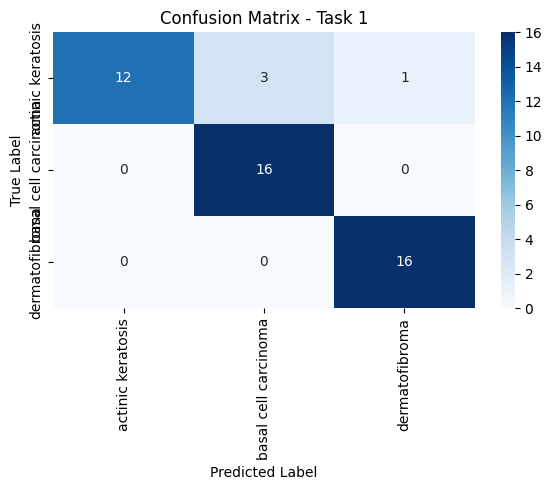


CONFUSION MATRIX FOR TASK 2
Classes: ['melanoma', 'nevus', 'pigmented benign keratosis']

Confusion Matrix Values:

[[ 4  7  5]
 [ 0 14  2]
 [ 1  2 13]]


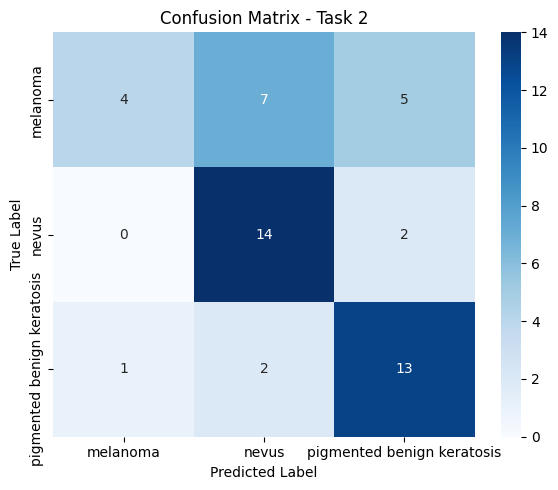


CONFUSION MATRIX FOR TASK 3
Classes: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

Confusion Matrix Values:

[[ 2  1  0]
 [ 0 15  1]
 [ 0  0  3]]


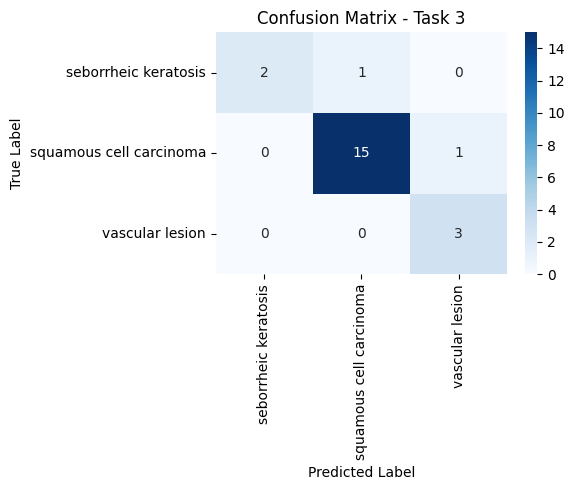

In [21]:
# CONFUSION MATRIX

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, Subset

model.eval()

for task_id, task_classes in enumerate(task_splits):

    print("\n====================================================")
    print(f"CONFUSION MATRIX FOR TASK {task_id+1}")
    print("Classes:", task_classes)
    print("====================================================")

    # class indices for the task
    task_class_indices = [class_to_idx[c] for c in task_classes]
    task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

    # select samples from test set belonging to task classes
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # restrict predictions to task classes
            outputs_task = outputs[:, task_class_indices]

            preds_idx = torch.argmax(outputs_task, dim=1)
            preds = task_class_indices_tensor[preds_idx]

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    # compute confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=task_class_indices)

    print("\nConfusion Matrix Values:\n")
    print(cm)

    # plot confusion matrix
    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=task_classes,
        yticklabels=task_classes
    )

    plt.title(f"Confusion Matrix - Task {task_id+1}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

#### ROC Curve (Multi-Class)

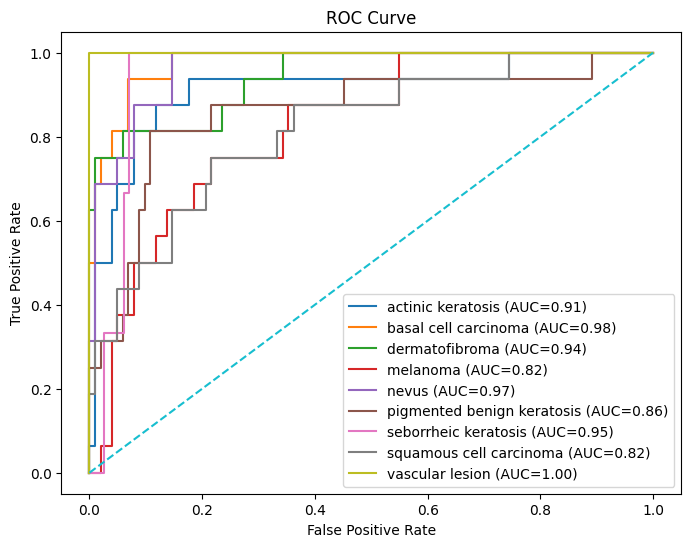

In [24]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import numpy as np

def plot_roc_curve(model):

    loader = DataLoader(full_test_dataset, batch_size=32)

    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:

            imgs = imgs.to(device)

            outputs = model(imgs)

            # Apply logit correction
            #if USE_LOGIT_CORRECTION and len(seen_classes) > len(current_classes):
                #bias_factor = len(current_classes) / len(seen_classes)
                #outputs[:, seen_classes[:-len(current_classes)]] *= bias_factor

            probs = torch.softmax(outputs, dim=1)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.numpy())

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    num_classes = len(full_test_dataset.classes)

    labels_bin = label_binarize(all_labels, classes=range(num_classes))

    plt.figure(figsize=(8,6))

    for i in range(num_classes):

        fpr, tpr, _ = roc_curve(labels_bin[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, label=f"{full_test_dataset.classes[i]} (AUC={roc_auc:.2f})")

    plt.plot([0,1], [0,1], linestyle="--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()

    plt.show()

plot_roc_curve(model)

#### Precision-Recall Curve

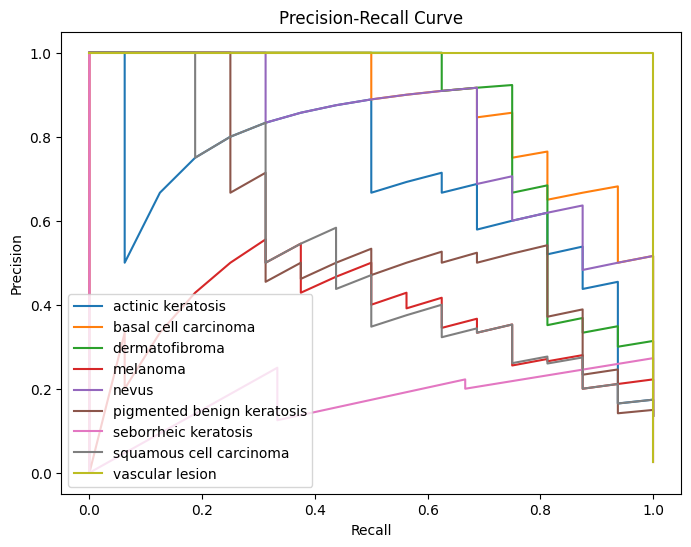

In [25]:
from sklearn.metrics import precision_recall_curve
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

def plot_precision_recall(model):

    loader = DataLoader(full_test_dataset, batch_size=32)

    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:

            imgs = imgs.to(device)

            outputs = model(imgs)

            # Apply logit correction
            #if USE_LOGIT_CORRECTION and len(seen_classes) > len(current_classes):
                #bias_factor = len(current_classes) / len(seen_classes)
                #outputs[:, seen_classes[:-len(current_classes)]] *= bias_factor

            probs = torch.softmax(outputs, dim=1)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.numpy())

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    num_classes = len(full_test_dataset.classes)

    labels_bin = label_binarize(all_labels, classes=range(num_classes))

    plt.figure(figsize=(8,6))

    for i in range(num_classes):

        precision, recall, _ = precision_recall_curve(
            labels_bin[:, i],
            all_probs[:, i]
        )

        plt.plot(recall, precision, label=full_test_dataset.classes[i])

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()

    plt.show()

plot_precision_recall(model)

#### Task Accuracy Curve

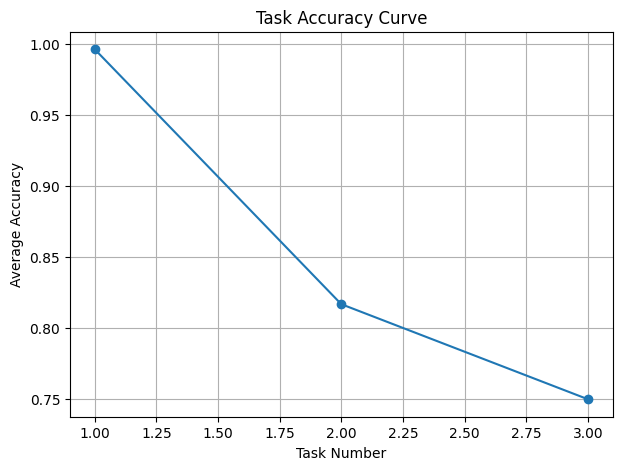

In [26]:
import matplotlib.pyplot as plt
import numpy as np

def plot_task_accuracy():

    task_acc = []

    for i in range(num_tasks):
        acc = np.mean(accuracy_matrix[i, :i+1])
        task_acc.append(acc)

    plt.figure(figsize=(7,5))

    plt.plot(range(1, num_tasks+1), task_acc, marker='o')

    plt.xlabel("Task Number")
    plt.ylabel("Average Accuracy")
    plt.title("Task Accuracy Curve")

    plt.grid(True)

    plt.show()

plot_task_accuracy()

#### Forgetting Curve

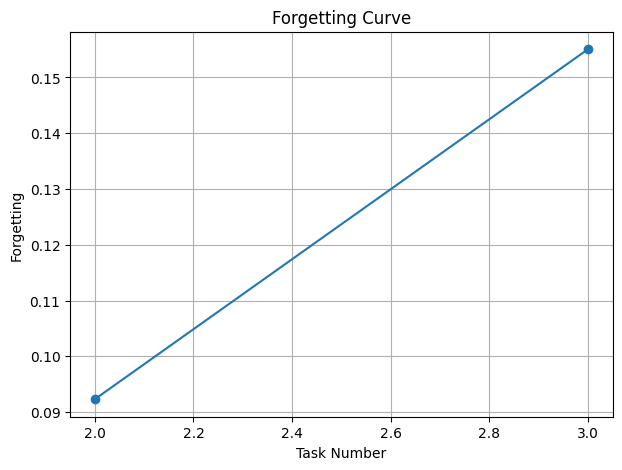

In [27]:
def plot_forgetting_curve():

    forgetting_scores = []

    for t in range(1, num_tasks):

        forgetting = []

        for i in range(t):

            max_prev = np.max(accuracy_matrix[:t+1, i])
            forgetting.append(max_prev - accuracy_matrix[t, i])

        forgetting_scores.append(np.mean(forgetting))

    plt.figure(figsize=(7,5))

    plt.plot(range(2, num_tasks+1), forgetting_scores, marker='o')

    plt.xlabel("Task Number")
    plt.ylabel("Forgetting")
    plt.title("Forgetting Curve")

    plt.grid(True)

    plt.show()

plot_forgetting_curve()

#### t-SNE Feature Visualization

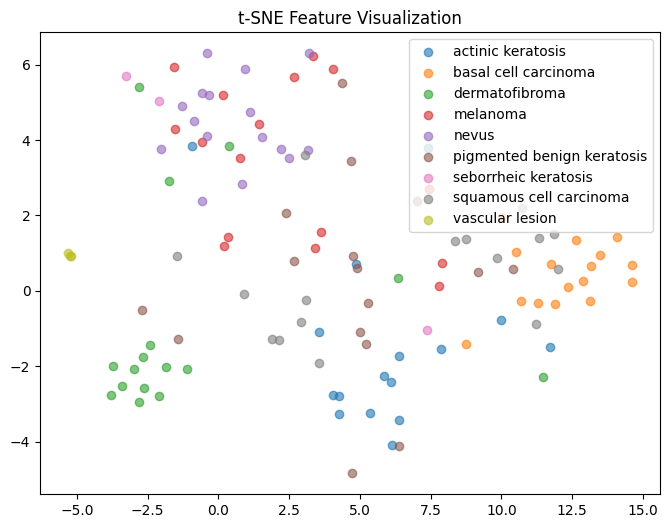

In [28]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

def plot_tsne_features(model):

    loader = DataLoader(full_test_dataset, batch_size=32)

    model.eval()

    features = []
    labels = []

    with torch.no_grad():
        for imgs, lbls in loader:

            imgs = imgs.to(device)

            feat = extract_features(model, imgs)

            features.extend(feat.cpu().numpy())
            labels.extend(lbls.numpy())

    features = np.array(features)
    labels = np.array(labels)

    tsne = TSNE(n_components=2, random_state=42, perplexity=30)

    reduced = tsne.fit_transform(features)

    plt.figure(figsize=(8,6))

    for cls in np.unique(labels):

        idx = labels == cls

        plt.scatter(
            reduced[idx,0],
            reduced[idx,1],
            label=full_test_dataset.classes[cls],
            alpha=0.6
        )

    plt.legend()
    plt.title("t-SNE Feature Visualization")

    plt.show()

plot_tsne_features(model)

#### Model Save

In [29]:
# SAVE FINAL MODEL

MODEL_PATH = "vit_cil_skin_lesion_model.pth"

torch.save({
    'model_state_dict': model.state_dict(),
    'seen_classes': seen_classes,
    'class_names': full_train_dataset.classes
}, MODEL_PATH)

print(f"Model saved successfully at: {MODEL_PATH}")

Model saved successfully at: vit_cil_skin_lesion_model.pth


In [30]:
from google.colab import files

files.download("vit_cil_skin_lesion_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# OVERALL TASK-AWARE ROC CURVE

import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

model.eval()

all_true = []
all_scores = []

num_classes = len(full_test_dataset.classes)
all_class_indices = list(range(num_classes))

for task_id, task_classes in enumerate(task_splits):

    # task class indices
    task_class_indices = [class_to_idx[c] for c in task_classes]

    # subset of full test dataset belonging to current task
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # task-aware restriction
            outputs_task = outputs[:, task_class_indices]
            probs_task = torch.softmax(outputs_task, dim=1)

            # place task probabilities into full class probability vector
            probs_full = torch.zeros(images.size(0), num_classes, device=device)
            probs_full[:, task_class_indices] = probs_task

            all_true.extend(labels.cpu().numpy())
            all_scores.append(probs_full.cpu().numpy())

all_true = np.array(all_true)
all_scores = np.concatenate(all_scores, axis=0)

# binarize labels
y_true_bin = label_binarize(all_true, classes=all_class_indices)

# ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in all_class_indices:
    if y_true_bin[:, i].sum() > 0:  # class present
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_scores[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

# micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), all_scores.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in all_class_indices if i in fpr]))
mean_tpr = np.zeros_like(all_fpr)

valid_classes = [i for i in all_class_indices if i in fpr]
for i in valid_classes:
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= len(valid_classes)

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# plot
plt.figure(figsize=(10, 8))

plt.plot(
    fpr["micro"], tpr["micro"],
    label=f"micro-average ROC (AUC = {roc_auc['micro']:.4f})",
    linewidth=2
)

plt.plot(
    fpr["macro"], tpr["macro"],
    label=f"macro-average ROC (AUC = {roc_auc['macro']:.4f})",
    linewidth=2
)

for i in valid_classes:
    plt.plot(
        fpr[i], tpr[i],
        label=f"{idx_to_class[i]} (AUC = {roc_auc[i]:.4f})",
        linewidth=1.5
    )

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

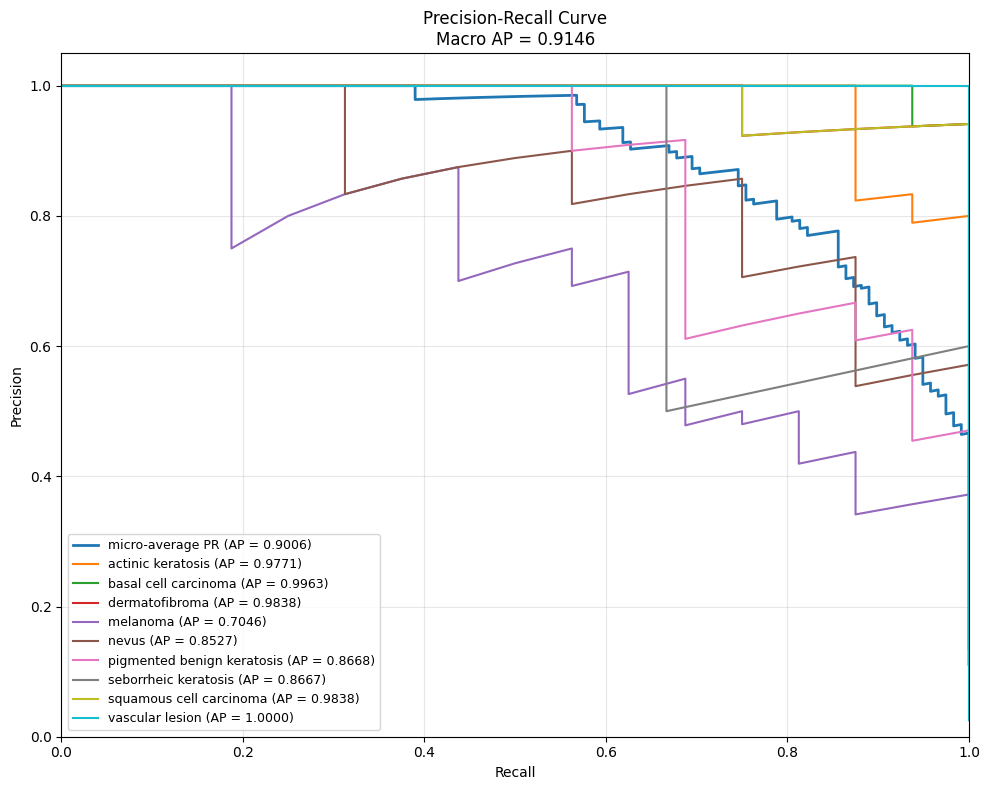

In [43]:
# =========================================================
# OVERALL TASK-AWARE PRECISION-RECALL CURVE
# =========================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

model.eval()

all_true = []
all_scores = []

num_classes = len(full_test_dataset.classes)
all_class_indices = list(range(num_classes))

for task_id, task_classes in enumerate(task_splits):

    # task class indices
    task_class_indices = [class_to_idx[c] for c in task_classes]

    # subset of full test dataset belonging to current task
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # task-aware restriction
            outputs_task = outputs[:, task_class_indices]
            probs_task = torch.softmax(outputs_task, dim=1)

            # place task probabilities into full class probability vector
            probs_full = torch.zeros(images.size(0), num_classes, device=device)
            probs_full[:, task_class_indices] = probs_task

            all_true.extend(labels.cpu().numpy())
            all_scores.append(probs_full.cpu().numpy())

all_true = np.array(all_true)
all_scores = np.concatenate(all_scores, axis=0)

# binarize labels
y_true_bin = label_binarize(all_true, classes=all_class_indices)

# PR for each class
precision = {}
recall = {}
avg_precision = {}

for i in all_class_indices:
    if y_true_bin[:, i].sum() > 0:  # class present
        precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], all_scores[:, i])
        avg_precision[i] = average_precision_score(y_true_bin[:, i], all_scores[:, i])

# micro-average PR
precision["micro"], recall["micro"], _ = precision_recall_curve(y_true_bin.ravel(), all_scores.ravel())
avg_precision["micro"] = average_precision_score(y_true_bin, all_scores, average="micro")

# macro-average AP
valid_classes = [i for i in all_class_indices if i in precision]
avg_precision["macro"] = np.mean([avg_precision[i] for i in valid_classes])

# plot
plt.figure(figsize=(10, 8))

plt.plot(
    recall["micro"], precision["micro"],
    label=f"micro-average PR (AP = {avg_precision['micro']:.4f})",
    linewidth=2
)

for i in valid_classes:
    plt.plot(
        recall[i], precision[i],
        label=f"{idx_to_class[i]} (AP = {avg_precision[i]:.4f})",
        linewidth=1.5
    )

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve\nMacro AP = {avg_precision['macro']:.4f}")
plt.legend(loc="lower left", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

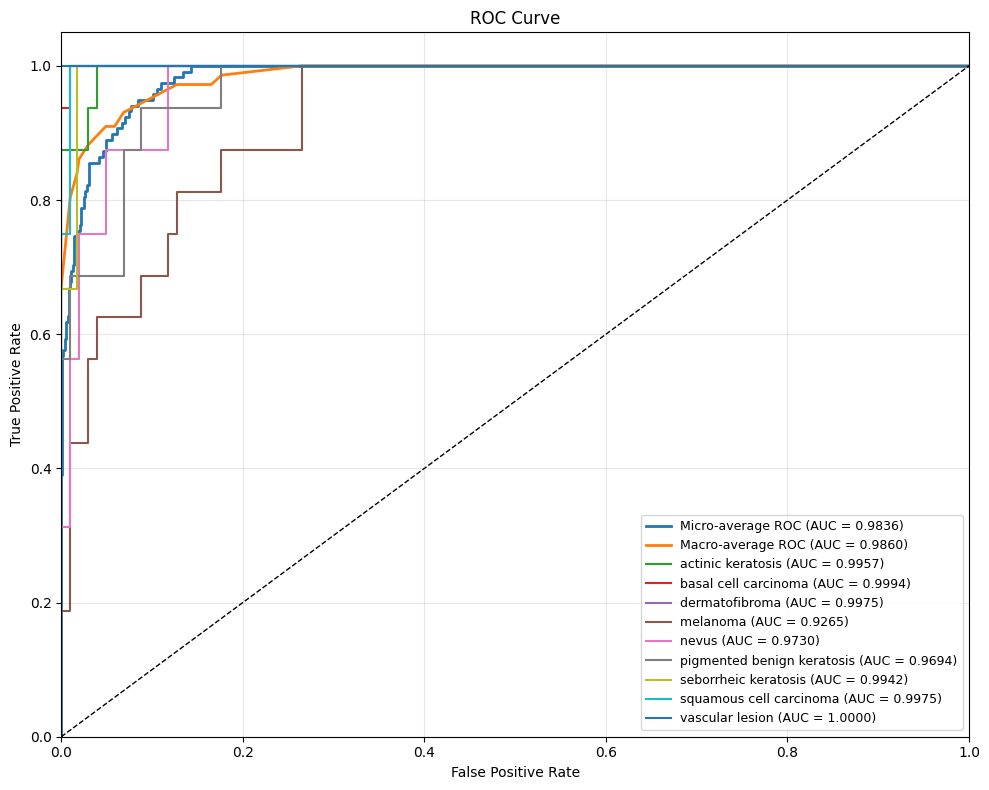

In [42]:
# OVERALL TASK-AWARE ROC CURVE

import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

model.eval()

all_true = []
all_scores = []

num_classes = len(full_test_dataset.classes)
all_class_indices = list(range(num_classes))

for task_id, task_classes in enumerate(task_splits):

    # class indices for this task
    task_class_indices = [class_to_idx[c] for c in task_classes]

    # select only samples of this task from full test set
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # task-aware restriction
            outputs_task = outputs[:, task_class_indices]
            probs_task = torch.softmax(outputs_task, dim=1)

            # place task probabilities back into full class space
            probs_full = torch.zeros(images.size(0), num_classes, device=device)
            probs_full[:, task_class_indices] = probs_task

            all_true.extend(labels.cpu().numpy())
            all_scores.append(probs_full.cpu().numpy())

all_true = np.array(all_true)
all_scores = np.concatenate(all_scores, axis=0)

# binarize true labels
y_true_bin = label_binarize(all_true, classes=all_class_indices)

fpr = {}
tpr = {}
roc_auc = {}

# per-class ROC
for i in all_class_indices:
    if y_true_bin[:, i].sum() > 0:
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_scores[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

# micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), all_scores.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# macro-average ROC
valid_classes = [i for i in all_class_indices if i in fpr]
all_fpr = np.unique(np.concatenate([fpr[i] for i in valid_classes]))
mean_tpr = np.zeros_like(all_fpr)

for i in valid_classes:
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= len(valid_classes)

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# plot
plt.figure(figsize=(10, 8))

plt.plot(
    fpr["micro"], tpr["micro"],
    linewidth=2,
    label=f"Micro-average ROC (AUC = {roc_auc['micro']:.4f})"
)

plt.plot(
    fpr["macro"], tpr["macro"],
    linewidth=2,
    label=f"Macro-average ROC (AUC = {roc_auc['macro']:.4f})"
)

for i in valid_classes:
    plt.plot(
        fpr[i], tpr[i],
        linewidth=1.5,
        label=f"{full_test_dataset.classes[i]} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# OVERALL TASK-AWARE METRICS

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader, Subset
import torch
import numpy as np

model.eval()

all_true = []
all_pred = []

for task_id, task_classes in enumerate(task_splits):

    # class indices for this task
    task_class_indices = [class_to_idx[c] for c in task_classes]
    task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

    # select samples belonging to this task
    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            # task-aware prediction
            outputs_task = outputs[:, task_class_indices]

            preds_idx = torch.argmax(outputs_task, dim=1)
            preds = task_class_indices_tensor[preds_idx]

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(preds.cpu().numpy())

# convert to numpy
all_true = np.array(all_true)
all_pred = np.array(all_pred)

accuracy = accuracy_score(all_true, all_pred)
precision = precision_score(all_true, all_pred, average='weighted', zero_division=0)
recall = recall_score(all_true, all_pred, average='weighted', zero_division=0)
f1 = f1_score(all_true, all_pred, average='weighted', zero_division=0)

print("OVERALL METRICS")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

OVERALL METRICS
Accuracy : 0.8051
Precision: 0.8281
Recall   : 0.8051
F1 Score : 0.7879


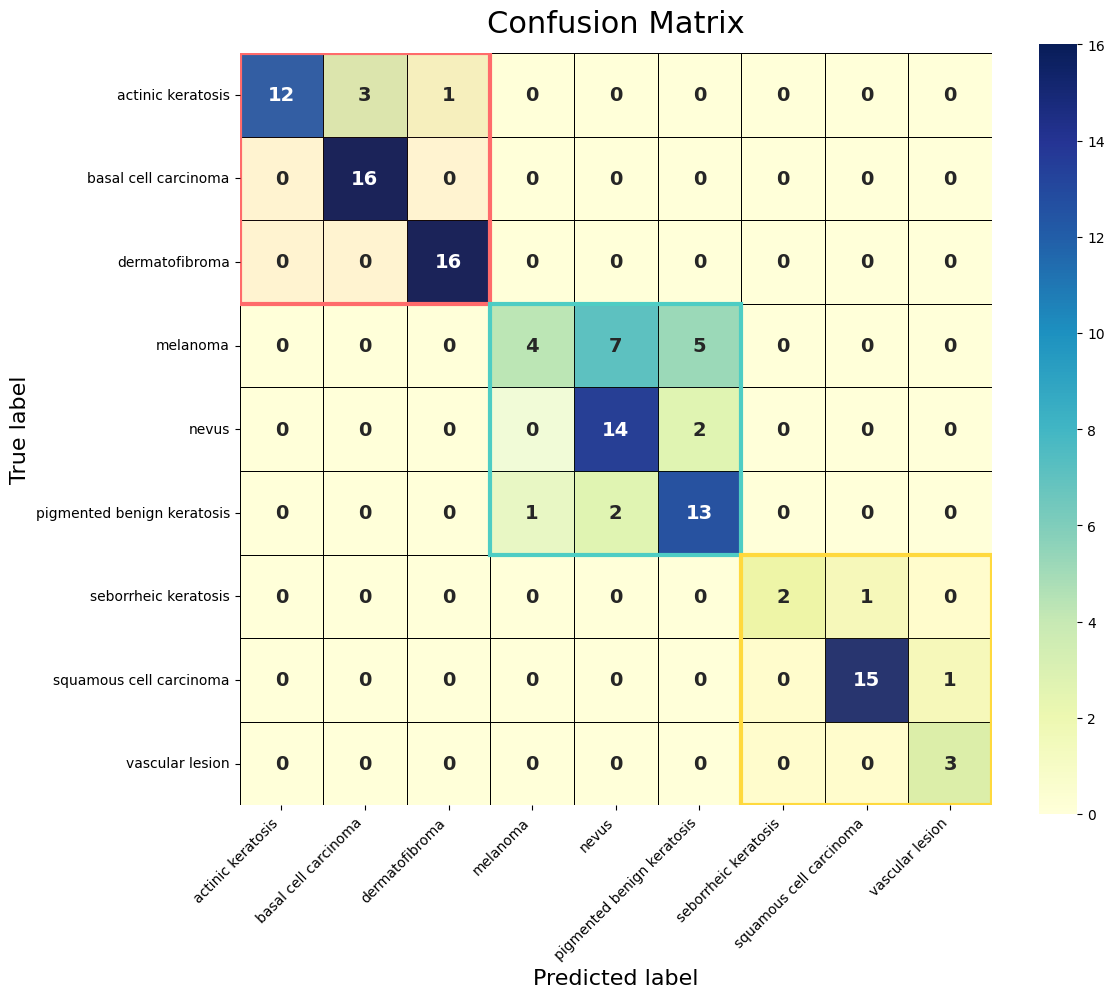

In [41]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, Subset
import matplotlib.patches as patches

model.eval()

all_true = []
all_pred = []

for task_id, task_classes in enumerate(task_splits):

    task_class_indices = [class_to_idx[c] for c in task_classes]
    task_class_indices_tensor = torch.tensor(task_class_indices, device=device)

    indices = [i for i, (_, label) in enumerate(full_test_dataset) if label in task_class_indices]
    task_subset = Subset(full_test_dataset, indices)

    loader = DataLoader(task_subset, batch_size=32, shuffle=False)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            outputs_task = outputs[:, task_class_indices]

            preds_idx = torch.argmax(outputs_task, dim=1)
            preds = task_class_indices_tensor[preds_idx]

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(preds.cpu().numpy())

# mapping
if 'idx_to_class' not in globals():
    idx_to_class = {v: k for k, v in class_to_idx.items()}

unique_labels = sorted(list(set(all_true)))
class_names = [idx_to_class[i] for i in unique_labels]

cm = confusion_matrix(all_true, all_pred, labels=unique_labels)

label_to_pos = {label: i for i, label in enumerate(unique_labels)}

plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=class_names,
    yticklabels=class_names,
    square=True,
    cbar=True,
    linewidths=0.5,
    linecolor='black',
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title("Confusion Matrix", fontsize=22, pad=15)
plt.xlabel("Predicted label", fontsize=16)
plt.ylabel("True label", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

task_colors = ['#FF6B6B', '#4ECDC4', '#FFD93D', '#6BCB77', '#845EC2']

for task_id, task_classes in enumerate(task_splits):

    task_class_indices = [class_to_idx[c] for c in task_classes if class_to_idx[c] in label_to_pos]

    if len(task_class_indices) == 0:
        continue

    task_positions = [label_to_pos[idx] for idx in task_class_indices]
    start = min(task_positions)
    end = max(task_positions)
    size = end - start + 1

    color = task_colors[task_id % len(task_colors)]

    # soft background shading
    rect_fill = patches.Rectangle(
        (start, start),
        size,
        size,
        fill=True,
        facecolor=color,
        alpha=0.08,
        edgecolor=None
    )
    ax.add_patch(rect_fill)

    # border
    rect_border = patches.Rectangle(
        (start, start),
        size,
        size,
        fill=False,
        edgecolor=color,
        linewidth=3
    )
    ax.add_patch(rect_border)

plt.tight_layout()
plt.show()